<a href="https://colab.research.google.com/github/zoriana-kutsa/Poland_apartment_prices/blob/main/Poland_apartment_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
folder = '/content/drive/MyDrive/archive'
print(sorted(os.listdir(folder)))

Mounted at /content/drive
['apartments_pl_2023_08.csv', 'apartments_pl_2023_09.csv', 'apartments_pl_2023_10.csv', 'apartments_pl_2023_11.csv', 'apartments_pl_2023_12.csv', 'apartments_pl_2024_01.csv', 'apartments_pl_2024_02.csv', 'apartments_pl_2024_03.csv', 'apartments_pl_2024_04.csv', 'apartments_pl_2024_05.csv', 'apartments_pl_2024_06.csv', 'apartments_rent_pl_2023_11.csv', 'apartments_rent_pl_2023_12.csv', 'apartments_rent_pl_2024_01.csv', 'apartments_rent_pl_2024_02.csv', 'apartments_rent_pl_2024_03.csv', 'apartments_rent_pl_2024_04.csv', 'apartments_rent_pl_2024_05.csv', 'apartments_rent_pl_2024_06.csv']


In [3]:
import pandas as pd

df = pd.read_csv(f'{folder}/apartments_pl_2024_06.csv')

print(df.shape)
df.head()

(21501, 28)


,id,city,type,squareMeters,rooms,floor,floorCount,buildYear,latitude,longitude,...,pharmacyDistance,ownership,buildingMaterial,condition,hasParkingSpace,hasBalcony,hasElevator,hasSecurity,hasStorageRoom,price
0,811891f98a870dfd6e414374a0a85560,szczecin,blockOfFlats,47.00,2.0,6.0,12.0,1981.0,53.428544,14.552812,...,0.085,condominium,concreteSlab,NaN,no,yes,yes,no,yes,449000
1,adaf636d0c44d8d9325bce42403eefee,szczecin,apartmentBuilding,88.22,3.0,1.0,2.0,2000.0,53.449093,14.516844,...,0.668,condominium,brick,premium,yes,yes,no,no,no,950000
2,9b957bd60885a469c96f17b58a914f4b,szczecin,apartmentBuilding,117.00,5.0,4.0,4.0,NaN,53.443096,14.561348,...,0.229,udział,brick,premium,yes,yes,no,no,no,1099000
3,74fef2ff7135bc70797a3fbfd7d44ed6,szczecin,blockOfFlats,33.31,1.0,1.0,4.0,1963.0,53.436100,14.541200,...,0.388,cooperative,brick,NaN,yes,no,no,yes,yes,380000
4,77cc78c75b0d09bf84d6d3124a28803c,szczecin,blockOfFlats,56.00,3.0,7.0,7.0,2018.0,53.447465,14.557811,...,0.178,condominium,brick,premium,yes,yes,yes,yes,yes,799000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21501 entries, 0 to 21500
Data columns (total 28 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    21501 non-null  object 
 1   city                  21501 non-null  object 
 2   type                  17104 non-null  object 
 3   squareMeters          21501 non-null  float64
 4   rooms                 21501 non-null  float64
 5   floor                 17928 non-null  float64
 6   floorCount            21292 non-null  float64
 7   buildYear             18121 non-null  float64
 8   latitude              21501 non-null  float64
 9   longitude             21501 non-null  float64
 10  centreDistance        21501 non-null  float64
 11  poiCount              21501 non-null  float64
 12  schoolDistance        21490 non-null  float64
 13  clinicDistance        21438 non-null  float64
 14  postOfficeDistance    21481 non-null  float64
 15  kindergartenDistanc

In [5]:
import glob

files = sorted(glob.glob(f'{folder}/apartments_pl_*.csv'))
print(len(files))

frames = []
for f in files:
    temp = pd.read_csv(f)
    temp['month'] = os.path.basename(f)[len('apartments_pl_'):-4]
    frames.append(temp)

sale = pd.concat(frames, ignore_index=True)
print(sale.shape)
sale['month'].value_counts().sort_index()

11
(195568, 29)


,count
month,
2023_08,18905
2023_09,16997
2023_10,16690
2023_11,16302
2023_12,16483
2024_01,15521
2024_02,16361
2024_03,17318
2024_04,19259


In [6]:
print('Total rows:', len(sale))
print('Unique ids:', sale['id'].nunique())

Total rows: 195568
Unique ids: 92967


In [7]:
sale = sale.sort_values('month').drop_duplicates(subset='id', keep='last')
print(sale.shape)

(92967, 29)


In [8]:
sale[['price', 'squareMeters', 'rooms']].describe()

,price,squareMeters,rooms
count,9.296700e+04,92967.000000,92967.000000
mean,7.675578e+05,56.451857,2.601450
std,3.960825e+05,20.265545,0.882564
min,1.500000e+05,25.000000,1.000000
25%,5.190000e+05,42.400000,2.000000
50%,6.850000e+05,52.600000,2.000000
75%,8.990000e+05,65.200000,3.000000
max,3.250000e+06,150.000000,6.000000


In [9]:
sale['price_m2'] = (sale['price'] / sale['squareMeters']).round(0)
sale['price_m2'].describe()

,price_m2
count,92967.000000
mean,13757.451386
std,4913.737024
min,3000.000000
25%,10000.000000
50%,13294.000000
75%,16883.000000
max,32097.000000


In [28]:
sale['city'].value_counts()

,count
city,
Warszawa,31982
Kraków,14186
Wrocław,9598
Gdańsk,8244
Łódź,7073
Poznań,3639
Bydgoszcz,3627
Gdynia,3569
Szczecin,2487


In [27]:
city_prices = (
    sale.groupby('city')['price_m2']
    .median()
    .sort_values(ascending=False)
    .round(0)
)
city_prices

,price_m2
city,
Warszawa,16766.0
Kraków,15000.0
Gdańsk,13230.0
Wrocław,12400.0
Gdynia,11683.0
Poznań,10618.0
Rzeszów,9975.0
Lublin,9205.0
Białystok,9042.0


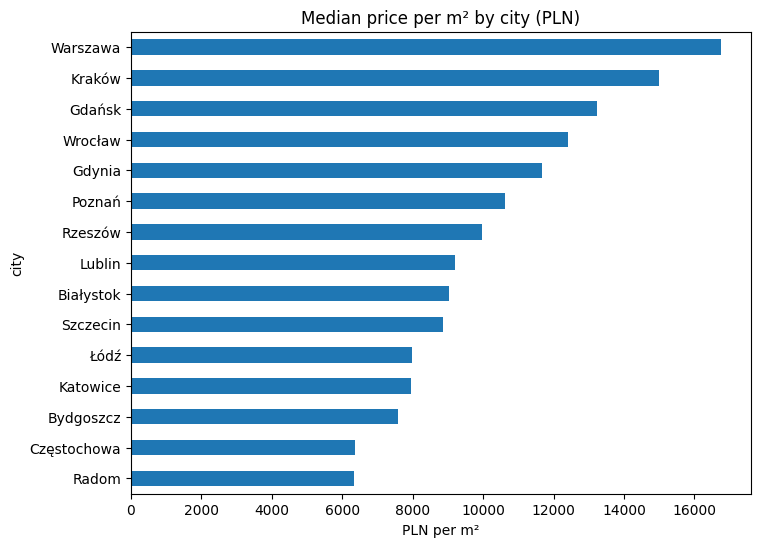

In [29]:
import matplotlib.pyplot as plt

city_prices.plot(kind='barh', figsize=(8, 6))
plt.title('Median price per m² by city (PLN)')
plt.xlabel('PLN per m²')
plt.gca().invert_yaxis()
plt.show()

In [13]:
city_names = {
    'warszawa': 'Warszawa',
    'krakow': 'Kraków',
    'gdansk': 'Gdańsk',
    'wroclaw': 'Wrocław',
    'gdynia': 'Gdynia',
    'poznan': 'Poznań',
    'rzeszow': 'Rzeszów',
    'lublin': 'Lublin',
    'bialystok': 'Białystok',
    'szczecin': 'Szczecin',
    'lodz': 'Łódź',
    'katowice': 'Katowice',
    'bydgoszcz': 'Bydgoszcz',
    'czestochowa': 'Częstochowa',
    'radom': 'Radom',
}

sale['city'] = sale['city'].map(city_names).fillna(sale['city'].str.title())
sale['city'].value_counts()

,count
city,
Warszawa,31982
Kraków,14186
Wrocław,9598
Gdańsk,8244
Łódź,7073
Poznań,3639
Bydgoszcz,3627
Gdynia,3569
Szczecin,2487


In [14]:
warsaw = sale[sale['city'] == 'Warszawa'].copy()
print(warsaw.shape)
warsaw['price_m2'].describe()

(31982, 30)


,price_m2
count,31982.000000
mean,17199.529704
std,4095.581370
min,7000.000000
25%,14245.000000
50%,16766.000000
75%,19567.000000
max,31042.000000


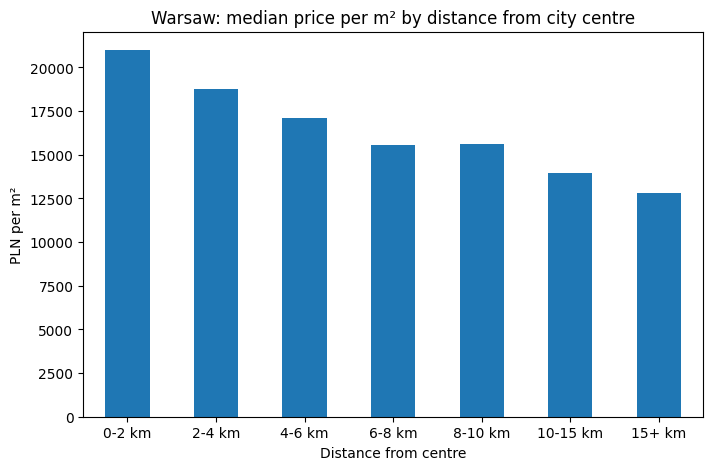

In [15]:
warsaw['distance_group'] = pd.cut(
    warsaw['centreDistance'],
    bins=[0, 2, 4, 6, 8, 10, 15, 30],
    labels=['0-2 km', '2-4 km', '4-6 km', '6-8 km', '8-10 km', '10-15 km', '15+ km']
)

distance_prices = warsaw.groupby('distance_group', observed=True)['price_m2'].median()

distance_prices.plot(kind='bar', figsize=(8, 5))
plt.title('Warsaw: median price per m² by distance from city centre')
plt.xlabel('Distance from centre')
plt.ylabel('PLN per m²')
plt.xticks(rotation=0)
plt.show()

In [16]:
rooms_prices = warsaw.groupby('rooms')['price_m2'].agg(['median', 'count'])
rooms_prices

,median,count
rooms,,
1.0,18999.5,2088
2.0,17343.5,13848
3.0,15702.0,11493
4.0,15652.0,3649
5.0,15769.0,697
6.0,15306.0,207


In [17]:
for col in ['hasElevator', 'hasParkingSpace', 'hasBalcony', 'hasSecurity', 'hasStorageRoom']:
    print(warsaw.groupby(col)['price_m2'].median().round(0), '\n')

hasElevator
no     15830.0
yes    17188.0
Name: price_m2, dtype: float64 

hasParkingSpace
no     16667.0
yes    16964.0
Name: price_m2, dtype: float64 

hasBalcony
no     17167.0
yes    16467.0
Name: price_m2, dtype: float64 

hasSecurity
no     16650.0
yes    17333.0
Name: price_m2, dtype: float64 

hasStorageRoom
no     17171.0
yes    16109.0
Name: price_m2, dtype: float64 



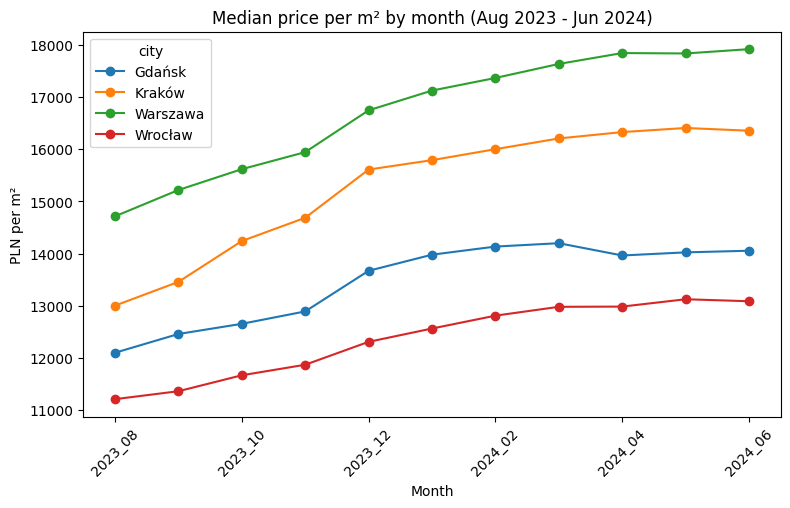

In [18]:
sale_all = pd.concat(frames, ignore_index=True)
sale_all['city'] = sale_all['city'].map(city_names).fillna(sale_all['city'].str.title())
sale_all['price_m2'] = sale_all['price'] / sale_all['squareMeters']

trend = (
    sale_all[sale_all['city'].isin(['Warszawa', 'Kraków', 'Wrocław', 'Gdańsk'])]
    .groupby(['month', 'city'])['price_m2']
    .median()
    .unstack()
)

trend.plot(figsize=(9, 5), marker='o')
plt.title('Median price per m² by month (Aug 2023 - Jun 2024)')
plt.xlabel('Month')
plt.ylabel('PLN per m²')
plt.xticks(rotation=45)
plt.show()

In [19]:
rent_files = sorted(glob.glob(f'{folder}/apartments_rent_pl_*.csv'))

rent_frames = []
for f in rent_files:
    temp = pd.read_csv(f)
    temp['month'] = os.path.basename(f)[len('apartments_rent_pl_'):-4]
    rent_frames.append(temp)

rent_all = pd.concat(rent_frames, ignore_index=True)
rent_all['city'] = rent_all['city'].map(city_names).fillna(rent_all['city'].str.title())
rent_all['rent_m2'] = rent_all['price'] / rent_all['squareMeters']

print(rent_all.shape)
rent_all['month'].value_counts().sort_index()

(70847, 30)


,count
month,
2023_11,8533
2023_12,8872
2024_01,8430
2024_02,8318
2024_03,9152
2024_04,9484
2024_05,9209
2024_06,8849


In [20]:
latest = '2024_06'

buy = sale_all[sale_all['month'] == latest].groupby('city')['price_m2'].median()
rent = rent_all[rent_all['month'] == latest].groupby('city')['rent_m2'].median()

yield_df = pd.DataFrame({'price_m2': buy, 'rent_m2': rent})
yield_df['gross_yield_%'] = (yield_df['rent_m2'] * 12 / yield_df['price_m2'] * 100).round(1)
yield_df.sort_values('gross_yield_%', ascending=False).round(0)

,price_m2,rent_m2,gross_yield_%
city,,,
Bydgoszcz,7987.0,46.0,7.0
Szczecin,9216.0,54.0,7.0
Radom,6700.0,39.0,7.0
Katowice,8462.0,48.0,7.0
Częstochowa,6889.0,39.0,7.0
Łódź,8317.0,46.0,7.0
Lublin,9890.0,53.0,6.0
Poznań,11019.0,53.0,6.0
Rzeszów,10811.0,51.0,6.0


In [21]:
nbp_file = f'{folder}/ceny_mieszkan.xlsx'
raw = pd.read_excel(nbp_file, sheet_name='Rynek wtórny', header=None)

def read_block(first_col, last_col, label):
    block = raw.iloc[7:, first_col:last_col + 1].copy()
    block.columns = raw.iloc[6, first_col:last_col + 1].tolist()
    block = block.rename(columns={'Kwartał': 'quarter'})
    block = block.dropna(subset=['quarter'])
    long = block.melt(id_vars='quarter', var_name='city', value_name=label)
    long[label] = pd.to_numeric(long[label], errors='coerce')
    return long

offer = read_block(0, 17, 'nbp_offer_m2')
trans = read_block(23, 40, 'nbp_transaction_m2')

nbp = offer.merge(trans, on=['quarter', 'city'])
nbp['quarter'] = nbp['quarter'].astype(str).str.strip()
parts = nbp['quarter'].str.split(' ', expand=True)
roman = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
nbp['period'] = pd.PeriodIndex(parts[1] + 'Q' + parts[0].map(roman).astype(str), freq='Q')
nbp = nbp.dropna(subset=['nbp_offer_m2', 'nbp_transaction_m2'], how='all')

print(nbp.shape)
nbp.tail()

(1360, 5)


,quarter,city,nbp_offer_m2,nbp_transaction_m2,period
1355,II 2025,Zielona Góra,8790.413974,8075.312652,2025Q2
1356,III 2025,Zielona Góra,8740.917042,8641.586336,2025Q3
1357,IV 2025,Zielona Góra,8838.511360,8787.374371,2025Q4
1358,I 2026,Zielona Góra,9071.203535,8553.681874,2026Q1
1359,II 2026,Zielona Góra,9183.309383,8633.384045,2026Q2


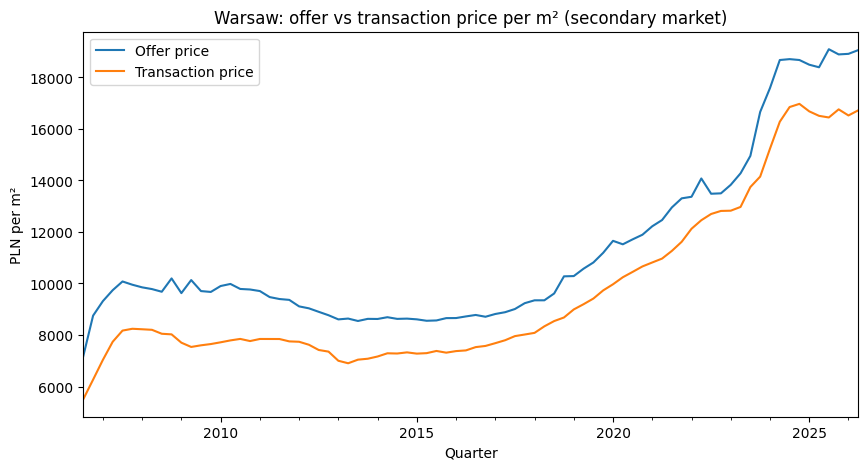

In [22]:
wa = nbp[nbp['city'] == 'Warszawa'].set_index('period')

wa[['nbp_offer_m2', 'nbp_transaction_m2']].plot(figsize=(10, 5))
plt.title('Warsaw: offer vs transaction price per m² (secondary market)')
plt.xlabel('Quarter')
plt.ylabel('PLN per m²')
plt.legend(['Offer price', 'Transaction price'])
plt.show()

In [23]:
kaggle_q2 = (
    sale_all[sale_all['month'].isin(['2024_04', '2024_05', '2024_06'])]
    .groupby('city')['price_m2'].median()
    .rename('kaggle_listing_m2')
)

nbp_q2 = nbp[nbp['period'] == '2024Q2'].set_index('city')[['nbp_offer_m2', 'nbp_transaction_m2']]

compare = nbp_q2.join(kaggle_q2, how='inner').round(0)
compare['listing_vs_transaction_%'] = (
    (compare['kaggle_listing_m2'] / compare['nbp_transaction_m2'] - 1) * 100
).round(1)

compare.sort_values('nbp_transaction_m2', ascending=False)

,nbp_offer_m2,nbp_transaction_m2,kaggle_listing_m2,listing_vs_transaction_%
city,,,,
Warszawa,18675.0,16279.0,17857.0,9.7
Kraków,16816.0,14745.0,16355.0,10.9
Gdańsk,14776.0,12660.0,14000.0,10.6
Wrocław,13678.0,12504.0,13067.0,4.5
Gdynia,12998.0,11413.0,12645.0,10.8
Poznań,11979.0,10357.0,10969.0,5.9
Rzeszów,10728.0,9934.0,10784.0,8.6
Lublin,10268.0,9624.0,9820.0,2.0
Szczecin,9563.0,9000.0,9174.0,1.9


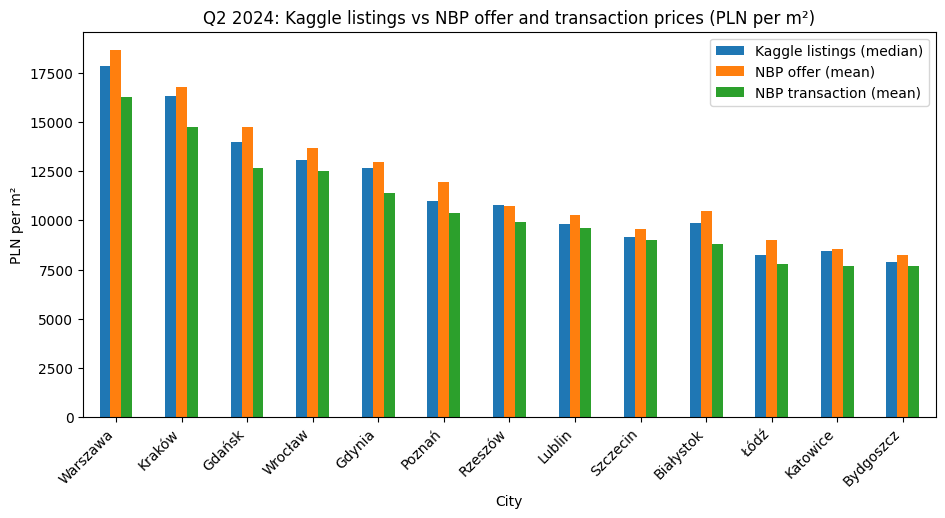

In [24]:
compare[['kaggle_listing_m2', 'nbp_offer_m2', 'nbp_transaction_m2']].sort_values(
    'nbp_transaction_m2', ascending=False
).plot(kind='bar', figsize=(11, 5))
plt.title('Q2 2024: Kaggle listings vs NBP offer and transaction prices (PLN per m²)')
plt.xlabel('City')
plt.ylabel('PLN per m²')
plt.legend(['Kaggle listings (median)', 'NBP offer (mean)', 'NBP transaction (mean)'])
plt.xticks(rotation=45, ha='right')
plt.show()

In [25]:
gap = compare['listing_vs_transaction_%']

print(f"Listings are above transaction prices in {(gap > 0).sum()} of {len(gap)} cities")
print(f"Gap range: {gap.min()}% to {gap.max()}%, median {gap.median()}%")
print(f"Largest gap: {gap.idxmax()}, smallest gap: {gap.idxmin()}")

Listings are above transaction prices in 13 of 13 cities
Gap range: 1.9% to 12.3%, median 8.6%
Largest gap: Białystok, smallest gap: Szczecin


## Key findings

- Asking prices from listings are higher than actual transaction prices in all 13 compared cities (gap from 1.9% to 12.3%, median 8.6%).
- The gap is largest in Białystok (12.3%) and smallest in Szczecin (1.9%).
- Warsaw is the most expensive market: transaction prices rose from about 16,300 PLN/m² in Q2 2024 to about 16,700 PLN/m² in Q2 2026 (NBP).
- Limitation: Kaggle data covers Aug 2023 - Jun 2024 and shows listing prices (median), while NBP shows mean prices, so the numbers are close but not identical.